# 02. Simulating production

**Notebook version:** v1.0.0 (2026-10-20) &nbsp;|&nbsp; All numbers are illustrative, not from any real company or process.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## Why simulate?
Real assembly lines are random: defects appear by chance and inspections sometimes miss them.
A **Monte Carlo simulation** imitates this by producing many virtual units, letting defects and inspections happen by chance, and averaging the cost.

To compare plans fairly, every plan is tested on the **same** virtual units ("common random numbers"), so a difference between plans is real, not luck.

In [2]:
from src.simulate import Draws, simulate_plan
from src.cost_model import expected_cost_analytic
draws = Draws(n_units=200_000, n_steps=3, seed=42)
plan = (0.25, 0.5, 1.0)   # check 25% after step 1, 50% after step 2, all after step 3
sim = simulate_plan(plan, draws)
exact = expected_cost_analytic(plan)
pd.DataFrame({"simulated": sim, "exact": exact}).round(3)

,simulated,exact
inspection,3.445,3.446
slowdown,1.722,1.723
scrap,3.375,3.382
escaped,1.948,1.948
total,10.490,10.498
std_error,0.076,NaN


## A built-in self-check
The simulation should agree with the exact calculation. The test suite (`tests/`) checks this automatically. Close agreement is how we know the simulation is wired correctly before we trust it on harder questions.

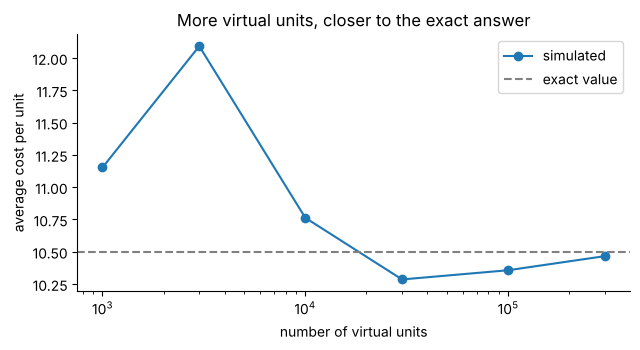

In [3]:
sizes = [1_000, 3_000, 10_000, 30_000, 100_000, 300_000]
est = []
for n in sizes:
    d = Draws(n, 3, seed=7)
    est.append(simulate_plan(plan, d)["total"])
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(sizes, est, "o-", label="simulated")
ax.axhline(exact["total"], color="gray", ls="--", label="exact value")
ax.set_xscale("log"); ax.set_xlabel("number of virtual units"); ax.set_ylabel("average cost per unit")
ax.set_title("More virtual units, closer to the exact answer"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway:** with enough virtual units the simulation settles on the exact answer. The simulation earns its keep when processes get more complicated than the exact formula can handle.